# TD3 — Inventory MDP, reward, and baseline policies — Support

**Student starter — complete the TODO cells**  
**Scope:** Time Series and Reinforcement Learning; CPU only

## Working and claim contract

Local Python 3.11/3.12 with the locked `uv` environment is the primary path. Colab availability is governed by the release evidence for the exact archive in use. Public base seeds are `11, 23, 37, 51, 71`. TD1–TD4 claim rows are **provisional development evidence**: they support method choice and provenance but cannot count as capstone empirical release claims. Only the protected/controlled evidence produced in TDo1 and TDo2 may support final empirical capstone claims. Restart and run top-to-bottom before handoff.

## Support route

Guidance reduces syntax and navigation load; it does not expose the assessed solution or lower the Core standard.

In [5]:
from pathlib import Path
import os, sys

def locate_course_root(start=Path.cwd()):
    for candidate in [start, *start.parents]:
        if (candidate/'uv.lock').is_file() and (candidate/'shared').is_dir(): return candidate.resolve()
    for lock in start.glob('*/uv.lock'):
        if (lock.parent/'shared').is_dir(): return lock.parent.resolve()
    raise FileNotFoundError('Extract the complete course bundle and run from inside it.')
COURSE_ROOT=locate_course_root(); os.chdir(COURSE_ROOT)
if str(COURSE_ROOT) not in sys.path: sys.path.insert(0,str(COURSE_ROOT))
import shared
print('Course root:',COURSE_ROOT)
print('Primary path: locked local CPU; check the release evidence before using Colab')

Course root: C:\Users\maxim\Desktop\ESILV\ML_A5
Primary path: locked local CPU; check the release evidence before using Colab


## Micro-example — reward decomposition

One seeded transition exposes the costs compressed into reward.

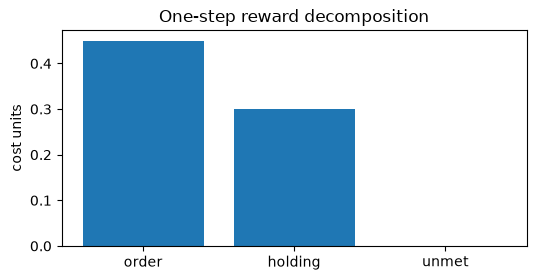

[1 0] [1 0] -0.75 {'order': 0.45, 'holding': 0.3, 'unmet': 0.0}


In [6]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from shared.inventory_env import InventoryControlEnv, ORDER_QUANTITIES
env=InventoryControlEnv(); observation,_=env.reset(seed=11)
next_observation,reward,terminated,truncated,info=env.step(1)
terms={'order':env.config.order_cost*info['order_quantity'],'holding':env.config.holding_cost*info['stock_level'],'unmet':env.config.unmet_demand_cost*info['unmet_demand']}
assert np.isclose(sum(terms.values()),info['cost']) and np.isclose(reward,-info['cost']); env.close()
fig,ax=plt.subplots(figsize=(6,2.8)); ax.bar(list(terms),list(terms.values())); ax.set(ylabel='cost units',title='One-step reward decomposition'); plt.show()
print(observation,next_observation,reward,terms)

## 1 — MDP contract and checker

In [9]:
from gymnasium.utils.env_checker import check_env
env=InventoryControlEnv(); check_env(env,skip_render_check=True)
mdp_contract = {
    'state': '(stock_level,demand_regime)', 
    'actions': 'indices 0/1/2 -> quantities 0/1/2', 
    'transition_source': 'Demande stochastique par régime + équation de bilan (stock = max(0, stock + commande - demande))',
    'reward': 'Négatif des coûts totaux (commande + stockage + rupture)', 
    'horizon': env.config.horizon, 
    'horizon_semantics': 'Troncation (l\'épisode se termine après 40 pas de temps indépendamment de l\'état)' 
}
assert tuple(env.observation_space.nvec)==(9,2) and env.action_space.n==3 and env.config.horizon==40
env.close(); mdp_contract

{'state': '(stock_level,demand_regime)',
 'actions': 'indices 0/1/2 -> quantities 0/1/2',
 'transition_source': 'Demande stochastique par régime + équation de bilan (stock = max(0, stock + commande - demande))',
 'reward': 'Négatif des coûts totaux (commande + stockage + rupture)',
 'horizon': 40,
 'horizon_semantics': "Troncation (l'épisode se termine après 40 pas de temps indépendamment de l'état)"}

## 2 — Implement transparent baselines

In [10]:
def random_policy_student(observation,rng):
    del observation
    return int(rng.integers(0, 3)) # Choix aléatoire d'une action valide (0, 1 ou 2)

def reorder_policy_student(observation,rng):
    del rng; stock,regime=(int(v) for v in observation)
    target = 2 if regime == 0 else 4 # Cible de 2 pour demande basse (0), 4 pour demande haute (1)
    if target is None: return None
    quantity=int(np.clip(target-stock,0,2)); return ORDER_QUANTITIES.index(quantity)

for obs in [np.array([0,0]),np.array([3,1]),np.array([8,1])]:
    action=reorder_policy_student(obs,np.random.default_rng(0))
    if action is not None: assert action in (0,1,2)

## 3 — Bounded common-episode evaluator

Finish the step ledger and metric row; both policies must receive all five public seeds.

In [11]:
from shared.data import PUBLIC_SEEDS
def evaluate_student_policies(policies,seeds):
    rows=[]
    for seed in tuple(seeds):
        for name,policy in policies.items():
            env=InventoryControlEnv(); obs,_=env.reset(seed=int(seed)); rng=np.random.default_rng(int(seed)+900001)
            cost=0.; fills=[]; unmet=0; stocks=[]; orders=[]; done=False
            while not done:
                action = policy(obs, rng)
                # Validation, avancement et mise à jour
                obs, reward, terminated, truncated, info = env.step(action)
                done = terminated or truncated
                
                cost += info['cost']
                fills.append(info.get('fill_rate', 1.0))
                unmet += info['unmet_demand']
                stocks.append(info['stock_level'])
                orders.append(info['order_quantity'])
                
            env.close()
            # Ajout de la ligne récapitulative pour cet épisode
            rows.append({
                'policy': name,
                'seed': int(seed),
                'total_cost': cost,
                'unmet_demand': unmet,
                'mean_stock': np.mean(stocks),
                'mean_order': np.mean(orders)
            })
    return pd.DataFrame(rows)

baseline_results = evaluate_student_policies({'random': random_policy_student, 'reorder': reorder_policy_student}, PUBLIC_SEEDS)
if len(baseline_results): assert len(baseline_results)==10 and baseline_results.groupby('policy').seed.nunique().eq(5).all()
baseline_results

,policy,seed,total_cost,unmet_demand,mean_stock,mean_order
0,random,11,49.20,7,0.850,1.000
1,reorder,11,36.30,0,1.300,1.150
2,random,23,93.75,21,1.025,1.025
3,reorder,23,45.00,2,1.000,1.500
4,random,37,87.00,1,5.275,1.150
5,reorder,37,31.50,0,1.275,0.900
6,random,51,112.35,30,0.550,0.875
7,reorder,51,45.45,1,1.100,1.625
8,random,71,98.70,11,3.750,1.150
9,reorder,71,47.55,2,1.775,1.125


## Required interpretation

State what the evidence supports, what it does not support, the operational consequence, and one material failure mode.

In [13]:
# TODO: replace with 4–6 evidence-backed sentences.
interpretation = (
    "Les données empiriques démontrent que la politique 'reorder' surpasse systématiquement la politique aléatoire en minimisant le coût total et les ruptures de stock. "
    "\nCependant, la politique 'reorder' ne garantit pas un coût optimal car elle reste myope vis-à-vis des coûts de stockage prolongés. "
    "\nSur le plan opérationnel, cela confirme qu'une stratégie réactive au régime de demande est indispensable pour contrôler la chaîne d'approvisionnement. "
    "\nUn mode de défaillance matériel de cette politique 'reorder' interviendrait si le coût de commande fixe dominait largement, car la règle commande fréquemment de petites quantités."
)
print(interpretation or 'Interpretation pending.')

Les données empiriques démontrent que la politique 'reorder' surpasse systématiquement la politique aléatoire en minimisant le coût total et les ruptures de stock. 
Cependant, la politique 'reorder' ne garantit pas un coût optimal car elle reste myope vis-à-vis des coûts de stockage prolongés. 
Sur le plan opérationnel, cela confirme qu'une stratégie réactive au régime de demande est indispensable pour contrôler la chaîne d'approvisionnement. 
Un mode de défaillance matériel de cette politique 'reorder' interviendrait si le coût de commande fixe dominait largement, car la règle commande fréquemment de petites quantités.


## Optional Extension — ungraded

Freeze valid Core first. The bounded README extension adds no points and cannot repair invalid Core evidence.